In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

print("Librerías importadas correctamente")


Librerías importadas correctamente


In [2]:

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"

df = pd.read_csv(url)

# Guardar una copia junto al notebook
df.to_csv("mpg.csv", index=False)

print("Archivo mpg.csv guardado correctamente")
print("Dimensiones:", df.shape)
display(df.head())


Archivo mpg.csv guardado correctamente
Dimensiones: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [3]:

# Mostrar las dimensiones y las primeras filas
print("Dimensiones del dataset:", df.shape)
display(df.head())

# Revisar los tipos de datos
df.info()

# Contar valores faltantes
print("\nValores faltantes por columna:")
display(df.isna().sum())

# Resumen estadístico
print("\nResumen estadístico:")
display(df.describe())


Dimensiones del dataset: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 35.9 KB

Valores faltantes por columna:


mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


Resumen estadístico:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [4]:

# Correlación de las variables numéricas con mpg
correlaciones = (
    df.select_dtypes(include="number")
      .corr()["mpg"]
      .sort_values(ascending=False)
)

print("Correlaciones con mpg:")
display(correlaciones)


Correlaciones con mpg:


mpg             1.000000
model_year      0.579267
acceleration    0.420289
cylinders      -0.775396
horsepower     -0.778427
displacement   -0.804203
weight         -0.831741
Name: mpg, dtype: float64

In [5]:

# Datos originales para las dos variables
datos_iniciales = df[["horsepower", "mpg"]].copy()

filas_antes = len(datos_iniciales)

# Eliminar filas con valores faltantes
datos = datos_iniciales.dropna().copy()

filas_despues = len(datos)
eliminadas = filas_antes - filas_despues
porcentaje = eliminadas / filas_antes * 100

print("Filas antes:", filas_antes)
print("Filas después:", filas_despues)
print("Filas eliminadas:", eliminadas)
print(f"Porcentaje eliminado: {porcentaje:.2f}%")

display(datos.head())


Filas antes: 398
Filas después: 392
Filas eliminadas: 6
Porcentaje eliminado: 1.51%


,horsepower,mpg
0,130.0,18.0
1,165.0,15.0
2,150.0,18.0
3,150.0,16.0
4,140.0,17.0


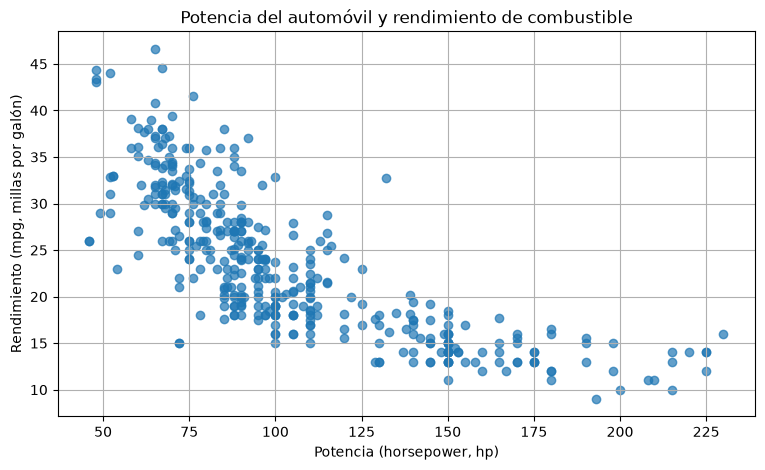

In [6]:

plt.figure(figsize=(9, 5))

plt.scatter(datos["horsepower"], datos["mpg"], alpha=0.7)

plt.title("Potencia del automóvil y rendimiento de combustible")
plt.xlabel("Potencia (horsepower, hp)")
plt.ylabel("Rendimiento (mpg, millas por galón)")
plt.grid(True)
plt.show()


In [7]:

X = datos[["horsepower"]]
y = datos["mpg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (313, 1)
X_test: (79, 1)
y_train: (313,)
y_test: (79,)


In [8]:

modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)

pred_lineal = modelo_lineal.predict(X_test)

rmse_lineal = np.sqrt(mean_squared_error(y_test, pred_lineal))
r2_lineal = r2_score(y_test, pred_lineal)

print(f"RMSE lineal: {rmse_lineal:.4f}")
print(f"R² lineal: {r2_lineal:.4f}")


RMSE lineal: 4.7067
R² lineal: 0.5660


RMSE grado 2: 4.2915
R² grado 2: 0.6392


,1,horsepower_escalado,horsepower_escalado^2
260,1.0,0.141429,0.020002
184,1.0,-0.329499,0.108569
174,1.0,-0.198685,0.039476


C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
C:\Users\USUARIO\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


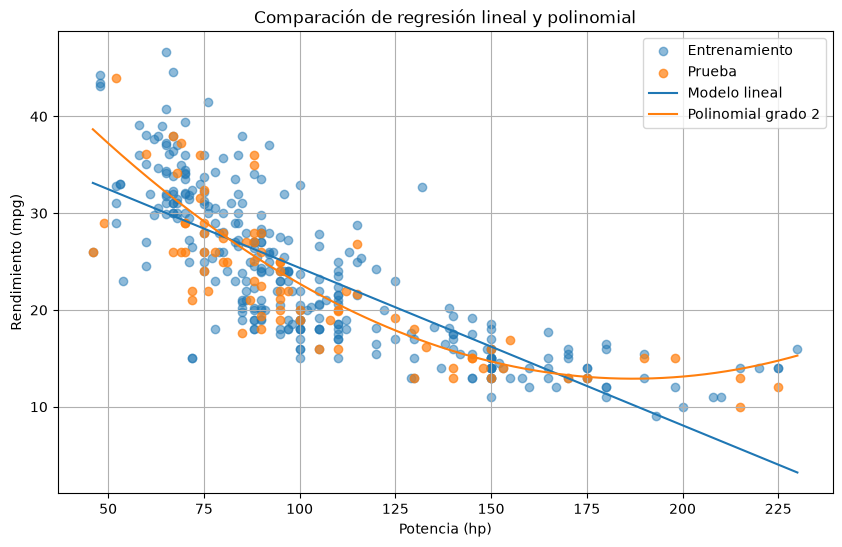

In [9]:

modelo_grado2 = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2),
    LinearRegression()
)

modelo_grado2.fit(X_train, y_train)

pred_grado2 = modelo_grado2.predict(X_test)

rmse_grado2 = np.sqrt(mean_squared_error(y_test, pred_grado2))
r2_grado2 = r2_score(y_test, pred_grado2)

print(f"RMSE grado 2: {rmse_grado2:.4f}")
print(f"R² grado 2: {r2_grado2:.4f}")

# Mostrar las columnas polinomiales de los tres primeros autos
escalador = modelo_grado2.named_steps["standardscaler"]
polinomio = modelo_grado2.named_steps["polynomialfeatures"]

X_tres = X_train.iloc[:3]
X_tres_escalado = escalador.transform(X_tres)
X_tres_poly = polinomio.transform(X_tres_escalado)

nombres = polinomio.get_feature_names_out(["horsepower_escalado"])
display(pd.DataFrame(X_tres_poly, columns=nombres, index=X_tres.index))

# Gráfico comparativo
x_suave = np.linspace(
    datos["horsepower"].min(),
    datos["horsepower"].max(),
    200
).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X_train["horsepower"], y_train, alpha=0.5, label="Entrenamiento")
plt.scatter(X_test["horsepower"], y_test, alpha=0.7, label="Prueba")
plt.plot(x_suave, modelo_lineal.predict(x_suave), label="Modelo lineal")
plt.plot(x_suave, modelo_grado2.predict(x_suave), label="Polinomial grado 2")

plt.xlabel("Potencia (hp)")
plt.ylabel("Rendimiento (mpg)")
plt.title("Comparación de regresión lineal y polinomial")
plt.grid(True)
plt.legend()
plt.show()


,grado,RMSE_validacion
0,1,4.958557
1,2,4.385783
2,3,4.390351
3,4,4.404014
4,5,4.354005
5,6,4.347532
6,7,4.354589
7,8,4.404464
8,9,4.422114
9,10,4.499858


Grado con menor RMSE: 6
RMSE mínimo: 4.3475


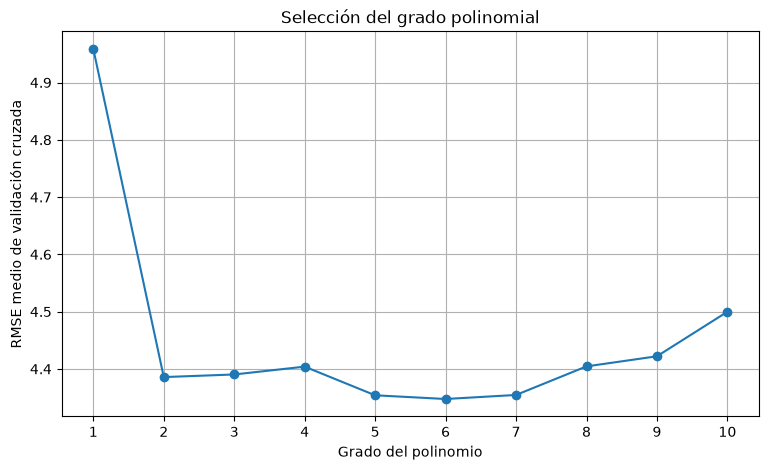

In [10]:

kf = KFold(n_splits=10, shuffle=True, random_state=42)

resultados = []

for grado in range(1, 11):
    modelo = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=grado),
        LinearRegression()
    )

    puntuaciones = cross_val_score(
        modelo,
        X_train,
        y_train,
        cv=kf,
        scoring="neg_root_mean_squared_error"
    )

    rmse_medio = -puntuaciones.mean()
    resultados.append({
        "grado": grado,
        "RMSE_validacion": rmse_medio
    })

tabla_grados = pd.DataFrame(resultados)
display(tabla_grados)

mejor_rmse = tabla_grados["RMSE_validacion"].min()
grado_minimo = int(
    tabla_grados.loc[
        tabla_grados["RMSE_validacion"].idxmin(), "grado"
    ]
)

# Elegir el grado con menor RMSE
grado_final = grado_minimo

print("Grado con menor RMSE:", grado_minimo)
print(f"RMSE mínimo: {mejor_rmse:.4f}")

plt.figure(figsize=(9, 5))
plt.plot(tabla_grados["grado"], tabla_grados["RMSE_validacion"], marker="o")
plt.xticks(range(1, 11))
plt.xlabel("Grado del polinomio")
plt.ylabel("RMSE medio de validación cruzada")
plt.title("Selección del grado polinomial")
plt.grid(True)
plt.show()


,Modelo,RMSE,R2
0,Regresión lineal,4.706723,0.565968
1,Polinomial grado 6,4.186512,0.656609


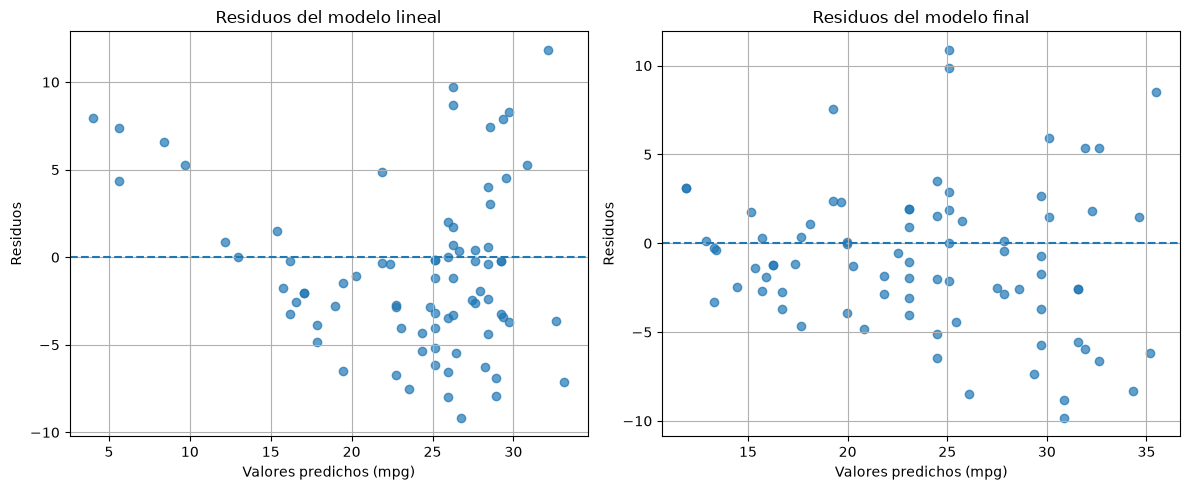

Ecuación del modelo en unidades originales:
Intercepto: 28.281968
Coeficiente de horsepower: -0.000000
Coeficiente de horsepower^2: -0.000000
Coeficiente de horsepower^3: -0.000000
Coeficiente de horsepower^4: -0.000000
Coeficiente de horsepower^5: -0.000000
Coeficiente de horsepower^6: 0.000000


In [11]:

# Modelo final con el grado seleccionado
modelo_final = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=grado_final),
    LinearRegression()
)

modelo_final.fit(X_train, y_train)
pred_final = modelo_final.predict(X_test)

rmse_final = np.sqrt(mean_squared_error(y_test, pred_final))
r2_final = r2_score(y_test, pred_final)

comparacion = pd.DataFrame({
    "Modelo": ["Regresión lineal", f"Polinomial grado {grado_final}"],
    "RMSE": [rmse_lineal, rmse_final],
    "R2": [r2_lineal, r2_final]
})

display(comparacion)

# Gráficos de residuos
residuos_lineal = y_test.to_numpy() - pred_lineal
residuos_final = y_test.to_numpy() - pred_final

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(pred_lineal, residuos_lineal, alpha=0.7)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Residuos del modelo lineal")
axes[0].set_xlabel("Valores predichos (mpg)")
axes[0].set_ylabel("Residuos")
axes[0].grid(True)

axes[1].scatter(pred_final, residuos_final, alpha=0.7)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Residuos del modelo final")
axes[1].set_xlabel("Valores predichos (mpg)")
axes[1].set_ylabel("Residuos")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Ajustar el modelo sin escalado para expresar la ecuación
poly_original = PolynomialFeatures(degree=grado_final)
X_train_poly = poly_original.fit_transform(X_train)

modelo_original = LinearRegression()
modelo_original.fit(X_train_poly, y_train)

nombres = poly_original.get_feature_names_out(["horsepower"])

print("Ecuación del modelo en unidades originales:")
print(f"Intercepto: {modelo_original.intercept_:.6f}")

for nombre, coef in zip(nombres[1:], modelo_original.coef_[1:]):
    print(f"Coeficiente de {nombre}: {coef:.6f}")


In [12]:

potencias = pd.DataFrame({"horsepower": [60, 100, 150, 200]})

predicciones = modelo_original.predict(
    poly_original.transform(potencias)
)

tabla_predicciones = pd.DataFrame({
    "Potencia (hp)": potencias["horsepower"],
    "Rendimiento predicho (mpg)": predicciones
})

display(tabla_predicciones)

# Analizar el vértice si el modelo es cuadrático
if grado_final == 2:
    beta1 = modelo_original.coef_[1]
    beta2 = modelo_original.coef_[2]

    if beta2 != 0:
        vertice = -beta1 / (2 * beta2)
        rendimiento_vertice = modelo_original.predict(
            poly_original.transform(pd.DataFrame({"horsepower": [vertice]}))
        )[0]

        print(f"Potencia del vértice: {vertice:.2f} hp")
        print(f"Rendimiento en el vértice: {rendimiento_vertice:.2f} mpg")
    else:
        print("No se puede calcular el vértice porque el término cuadrático es cero.")
else:
    print("El modelo elegido no es cuadrático; se analizará su curva.")

# Rango de potencias observado
print(
    "Rango observado de horsepower:",
    datos["horsepower"].min(),
    "a",
    datos["horsepower"].max(),
    "hp"
)


,Potencia (hp),Rendimiento predicho (mpg)
0,60,28.019581
1,100,25.686169
2,150,15.958196
3,200,7.480514


El modelo elegido no es cuadrático; se analizará su curva.
Rango observado de horsepower: 46.0 a 230.0 hp


In [13]:

print("CONCLUSIONES DE LA PRÁCTICA 3")
print("-" * 45)

print(
    f"El modelo lineal obtuvo un RMSE de {rmse_lineal:.4f} "
    f"y un R² de {r2_lineal:.4f}."
)

print(
    f"El modelo polinomial de grado {grado_final} obtuvo un RMSE de "
    f"{rmse_final:.4f} y un R² de {r2_final:.4f}."
)

if rmse_final < rmse_lineal:
    print("El modelo polinomial redujo el error respecto al modelo lineal.")
elif rmse_final > rmse_lineal:
    print("El modelo polinomial tuvo mayor error que el modelo lineal.")
else:
    print("Ambos modelos obtuvieron el mismo RMSE.")

print(
    "La regresión polinomial sigue siendo una regresión lineal "
    "porque estima sus coeficientes mediante una combinación lineal "
    "de las variables transformadas."
)

print(
    "Las predicciones deben interpretarse con precaución fuera del "
    "rango de potencias representado en los datos."
)


CONCLUSIONES DE LA PRÁCTICA 3
---------------------------------------------
El modelo lineal obtuvo un RMSE de 4.7067 y un R² de 0.5660.
El modelo polinomial de grado 6 obtuvo un RMSE de 4.1865 y un R² de 0.6566.
El modelo polinomial redujo el error respecto al modelo lineal.
La regresión polinomial sigue siendo una regresión lineal porque estima sus coeficientes mediante una combinación lineal de las variables transformadas.
Las predicciones deben interpretarse con precaución fuera del rango de potencias representado en los datos.


In [14]:
import os

print("Carpeta actual:", os.getcwd())
print("\nArchivos disponibles:")

for archivo in os.listdir():
    print(archivo)

Carpeta actual: C:\Users\USUARIO

Archivos disponibles:
.anaconda
.conda
.continuum
.gitconfig
.ipynb_checkpoints
.ipython
.jupyter
.ms-ad
.ollama
.packettracer
.th-client
.vscode
.vscode-shared
anaconda3
AppData
Cisco Packet Tracer 9.0.0
Configuración local
Contacts
Cookies
Datos de programa
Desktop
Documents
Downloads
Entorno de red
Examen Primer Parcial_INF672.ipynb
Examen_Primer_Parcial_INF672.ipynb
Favorites
Impresoras
IntelGraphicsProfiles
Links
Menú Inicio
Mis documentos
mpg.csv
Music
NTUSER.DAT
ntuser.dat.LOG1
ntuser.dat.LOG2
NTUSER.DAT{378e05d0-cfe5-11f0-91c3-a8e291f27b2a}.TM.blf
NTUSER.DAT{378e05d0-cfe5-11f0-91c3-a8e291f27b2a}.TMContainer00000000000000000001.regtrans-ms
NTUSER.DAT{378e05d0-cfe5-11f0-91c3-a8e291f27b2a}.TMContainer00000000000000000002.regtrans-ms
NTUSER.DAT{a2332f18-cdbf-11ec-8680-002248483d79}.TM.blf
NTUSER.DAT{a2332f18-cdbf-11ec-8680-002248483d79}.TMContainer00000000000000000001.regtrans-ms
NTUSER.DAT{a2332f18-cdbf-11ec-8680-002248483d79}.TMContainer000000000

In [16]:

import os

print("CARPETA:", os.getcwd())
print("\nARCHIVOS QUE HAY:")
print(os.listdir())


CARPETA: C:\Users\USUARIO

ARCHIVOS QUE HAY:
['.anaconda', '.conda', '.continuum', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.jupyter', '.ms-ad', '.ollama', '.packettracer', '.th-client', '.vscode', '.vscode-shared', 'anaconda3', 'AppData', 'Cisco Packet Tracer 9.0.0', 'Configuración local', 'Contacts', 'Cookies', 'Datos de programa', 'Desktop', 'Documents', 'Downloads', 'Entorno de red', 'Examen Primer Parcial_INF672.ipynb', 'Examen_Primer_Parcial_INF672.ipynb', 'Favorites', 'Impresoras', 'IntelGraphicsProfiles', 'Links', 'Menú Inicio', 'Mis documentos', 'mpg.csv', 'Music', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{378e05d0-cfe5-11f0-91c3-a8e291f27b2a}.TM.blf', 'NTUSER.DAT{378e05d0-cfe5-11f0-91c3-a8e291f27b2a}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{378e05d0-cfe5-11f0-91c3-a8e291f27b2a}.TMContainer00000000000000000002.regtrans-ms', 'NTUSER.DAT{a2332f18-cdbf-11ec-8680-002248483d79}.TM.blf', 'NTUSER.DAT{a2332f18-cdbf-11ec-8680-002248483d79}